In [497]:
import numpy as np
import pandas as pd

from sklearn.datasets import (load_diabetes,load_breast_cancer,load_digits,load_iris)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_squared_error,r2_score,accuracy_score,confusion_matrix,precision_recall_fscore_support)

In [498]:
diabetes = load_diabetes(scaled=False)
X_diabetes = diabetes.data
y_diabetes = diabetes.target

breast_cancer = load_breast_cancer()
X_breast = breast_cancer.data
y_breast = 1 - breast_cancer.target

digits = load_digits()
X_digits = digits.data / 16.0
y_digits = digits.target

iris = load_iris()
X_iris = iris.data
y_iris = iris.target


In [499]:
def split_dataset(X, y, classification=True):

    #20% for testing
    stratify_value = y if classification else None
    
    X_temp, X_test, y_temp, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=stratify_value)


    #25% of the remaining 80% for validation
    stratify_value = y_temp if classification else None

    X_train, X_val, y_train, y_val = train_test_split(
        X_temp,
        y_temp,
        test_size=0.25,
        random_state=42,
        stratify=stratify_value)

    return X_train, X_val, X_test, y_train, y_val, y_test


diabetes_split = split_dataset(X_diabetes, y_diabetes, classification=False)
breast_split = split_dataset(X_breast, y_breast)
digits_split = split_dataset(X_digits, y_digits)
iris_split = split_dataset(X_iris, y_iris)


In [500]:
datasets = {
    "Diabetes": diabetes_split,
    "Breast Cancer": breast_split,
    "Digits": digits_split,
    "Iris": iris_split
}

for name, split in datasets.items():

    X_train, X_val, X_test, y_train, y_val, y_test = split

    print("\n", name)

    print("Training size:", len(X_train))
    print("Validation size:", len(X_val))
    print("Testing size:", len(X_test))
    print("Total size:", len(X_train) + len(X_val) + len(X_test))

    if name != "Diabetes":
        print("\nTraining class counts:",
              np.unique(y_train, return_counts=True))

        print("Validation class counts:",
              np.unique(y_val, return_counts=True))

        print("Testing class counts:",
              np.unique(y_test, return_counts=True))




 Diabetes
Training size: 264
Validation size: 89
Testing size: 89
Total size: 442

 Breast Cancer
Training size: 341
Validation size: 114
Testing size: 114
Total size: 569

Training class counts: (array([0, 1]), array([214, 127]))
Validation class counts: (array([0, 1]), array([71, 43]))
Testing class counts: (array([0, 1]), array([72, 42]))

 Digits
Training size: 1077
Validation size: 360
Testing size: 360
Total size: 1797

Training class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([106, 109, 107, 109, 109, 109, 109, 107, 104, 108]))
Validation class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 37, 35, 37, 36, 36, 36, 36, 35, 36]))
Testing class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 36, 35, 37, 36, 37, 36, 36, 35, 36]))

 Iris
Training size: 90
Validation size: 30
Testing size: 30
Total size: 150

Training class counts: (array([0, 1, 2]), array([30, 30, 30]))
Validation class counts: (array([0, 1, 2]), array([10, 10, 10]))
Testing class c

In [501]:
class Standardizer:

    def fit(self, X):
        self.mean = np.mean(X, axis=0) #axis=0 means calculate the mean vertically, column by column.
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1  #avoid devision by 0
        return self

    def transform(self, X):
        return (X - self.mean) / self.std

    

In [502]:
def add_bias(X):
        # Add a column of ones at the beginning
        return np.column_stack((np.ones(X.shape[0]), X))

In [503]:
X_train, X_val, X_test, y_train, y_val, y_test = diabetes_split

scaler = Standardizer()
scaler.fit(X_train)

X_train_std = scaler.transform(X_train)
X_val_std = scaler.transform(X_val)
X_test_std = scaler.transform(X_test)

print("Training means:")
print(np.mean(X_train_std, axis=0))

print("\nTraining standard deviations:")
print(np.std(X_train_std, axis=0))

X_train_bias = add_bias(X_train_std)

print("\nShape before adding bias:", X_train_std.shape)
print("Shape after adding bias:", X_train_bias.shape)


Training means:
[-2.26249995e-16  1.79990702e-16 -2.23726761e-15 -3.61663561e-16
 -5.88754634e-17 -1.08348348e-17  1.94394164e-16 -4.03717464e-17
  2.03877319e-15 -5.53100810e-16]

Training standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Shape before adding bias: (264, 10)
Shape after adding bias: (264, 11)


We must calculate the mean and standard deviation using only the training data to prevent data leakage and ensure that validation and test data remain unseen during training. If we calculate them using all rows, information from the test data influences preprocessing, making the evaluation misleading because the model has indirectly used information from the test set.

In [504]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2(y_true, y_pred):

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_total)

In [505]:
def confusion_matrix(y, pred, K):
    cm = np.zeros((K, K), dtype=int) #k is number of classes
    np.add.at(cm, (y, pred), 1)
    return cm

In [506]:
def accuracy(y, pred):
    return np.mean(y == pred)


def classification_metrics(cm):

    tp = np.diag(cm)
    fp = np.sum(cm, axis=0) - tp
    fn = np.sum(cm, axis=1) - tp


    # precision = 0 if a class is never predicted
    precision = np.divide(
        tp,
        tp + fp,
        out=np.zeros_like(tp, dtype=float),
        where=(tp + fp) != 0
    )

    recall = np.divide(
        tp,
        tp + fn,
        out=np.zeros_like(tp, dtype=float),
        where=(tp + fn) != 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision, dtype=float),
        where=(precision + recall) != 0
    )

    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    }

In [507]:
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix as sklearn_confusion_matrix,
    precision_recall_fscore_support
)

np.random.seed(42)

y_reg = np.random.randn(500)
pred_reg = np.random.randn(500)

K = 4
N = 500

y = np.random.randint(0, K, N)
pred = np.random.randint(0, K, N)

In [508]:
assert np.isclose(
    mse(y_reg, pred_reg),
    mean_squared_error(y_reg, pred_reg),
    atol=1e-12
)

assert np.isclose(
    rmse(y_reg, pred_reg),
    np.sqrt(mean_squared_error(y_reg, pred_reg)),
    atol=1e-12
)

assert np.isclose(
    r2(y_reg, pred_reg),
    r2_score(y_reg, pred_reg),
    atol=1e-12
)


In [509]:
# Confusion matrix
cm = confusion_matrix(y, pred, K)

cm_sklearn = sklearn_confusion_matrix(
    y, pred, labels=np.arange(K)
)

assert np.array_equal(cm, cm_sklearn)


# Accuracy
assert np.isclose(
    accuracy(y, pred),
    accuracy_score(y, pred),
    atol=1e-12
)


# Precision, recall and F1
my_metrics = classification_metrics(cm)

p_sklearn, r_sklearn, f1_sklearn, _ = precision_recall_fscore_support(
    y,
    pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)


# Compare individual classes
assert np.allclose(
    my_metrics["precision"], p_sklearn, atol=1e-12
)

assert np.allclose(
    my_metrics["recall"], r_sklearn, atol=1e-12
)

assert np.allclose(
    my_metrics["f1"], f1_sklearn, atol=1e-12
)


# Compare macro averages
assert np.isclose(
    my_metrics["macro_precision"],
    np.mean(p_sklearn),
    atol=1e-12
)

assert np.isclose(
    my_metrics["macro_recall"],
    np.mean(r_sklearn),
    atol=1e-12
)

assert np.isclose(
    my_metrics["macro_f1"],
    np.mean(f1_sklearn),
    atol=1e-12
)

print("All metrics match sklearn!")

All metrics match sklearn!


In [510]:

def grad_check(f, grad, w):

    h = 1e-5
    numerical_grad = np.zeros_like(w, dtype=float)
    for i in range(len(w)):

        w_plus = w.copy()
        w_minus = w.copy()

        w_plus[i] += h
        w_minus[i] -= h

        numerical_grad[i] = (
            f(w_plus) - f(w_minus)
        ) / (2 * h)

    analytical_grad = grad(w)

    numerator = np.linalg.norm(
        numerical_grad - analytical_grad
    )

    denominator = (
        np.linalg.norm(numerical_grad)
        + np.linalg.norm(analytical_grad)
    )

    relative_error = numerator / denominator
    return relative_error


In [511]:

def f(w):
    return np.sum(w ** 2)

def grad(w):
    return 2 * w

w = np.array([2.0, 3.0, 4.0])
error = grad_check(f, grad, w)
print("Relative error:", error)

Relative error: 8.405699503414379e-12


///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////////

In [512]:
X_train, X_val, X_test, y_train, y_val, y_test = diabetes_split

# Standardize using training data only
scaler = Standardizer()
scaler.fit(X_train)

X_train_std = scaler.transform(X_train)
X_val_std = scaler.transform(X_val)
X_test_std = scaler.transform(X_test)

# Add bias column
X_train_bias = add_bias(X_train_std)
X_val_bias = add_bias(X_val_std)
X_test_bias = add_bias(X_test_std)

J(w) = (1 / 2N) (X̃w - y)ᵀ(X̃w - y)
J(w) = (1 / 2N) (wᵀX̃ᵀX̃w - 2yᵀX̃w + yᵀy)
∇J(w) = (1 / 2N) (2X̃ᵀX̃w - 2X̃ᵀy)
∇J(w) = (1 / N) (X̃ᵀX̃w - X̃ᵀy)

Set the gradient equal to zero:
(1 / N) (X̃ᵀX̃w - X̃ᵀy) = 0
X̃ᵀX̃w - X̃ᵀy = 0
X̃ᵀX̃w = X̃ᵀy

Multiply both sides by (X̃ᵀX̃)⁻¹:
w* = (X̃ᵀX̃)⁻¹ X̃ᵀy

In [513]:
def normal_equation(X, y):

    a = X.T @ X
    b = X.T @ y

    w = np.linalg.solve(a, b)  #solve the equatiom aw=b
    return w

w_star = normal_equation(X_train_bias, y_train)
print("Optimal weights:")
print(w_star)

Optimal weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]


In [514]:
# Predictions
y_train_pred = X_train_bias @ w_star
y_val_pred = X_val_bias @ w_star
y_test_pred = X_test_bias @ w_star

results = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "RMSE": [
        rmse(y_train, y_train_pred),
        rmse(y_val, y_val_pred),
        rmse(y_test, y_test_pred)
    ]
})

print(results)

print("\nTest R2:", r2(y_test, y_test_pred))

condition_number = np.linalg.cond(X_train_bias.T @ X_train_bias)
print("\nCondition number:", condition_number)

      Dataset       RMSE
0       Train  54.610364
1  Validation  51.193714
2        Test  54.156413

Test R2: 0.4464263764021128

Condition number: 505.70612269609745


In [515]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train_std, y_train)

# Combine sklearn intercept and coefficients
w_sklearn = np.concatenate((
    [linear_model.intercept_],
    linear_model.coef_
))

print("Our weights:")
print(w_star)

print("\nSklearn weights:")
print(w_sklearn)

print("\nMaximum absolute difference:",
      np.max(np.abs(w_star - w_sklearn)))

assert np.allclose(w_star, w_sklearn, atol=1e-6)


Our weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]

Sklearn weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]

Maximum absolute difference: 1.0089706847793423e-12


In [516]:
feature_names = ["Bias"] + list(diabetes.feature_names)

weights_table = pd.DataFrame({
    "Feature": feature_names,
    "Weight": w_star
})

print(weights_table)

   Feature      Weight
0     Bias  149.810606
1      age    1.131837
2      sex  -11.359311
3      bmi   25.076618
4       bp   15.167338
5       s1  -51.101359
6       s2   27.480823
7       s3   10.840294
8       s4   15.032148
9       s5   37.271588
10      s6    3.817112


In [517]:
for feature in ["s1", "s2", "bmi"]:
    index = feature_names.index(feature)
    print(feature, ":", w_star[index])

s1 : -51.10135942562618
s2 : 27.48082317876486
bmi : 25.07661841048503


The weight of s1 is negative (-51.10) and has a larger absolute magnitude than s2 (27.48) and bmi (25.08), which both have positive weights. This means that, while keeping the other features constant, an increase in s1 decreases the predicted target, whereas increases in s2 and bmi increase it. However, interpreting individual weights is risky because correlated features can share information, making their individual coefficients unstable and difficult to interpret independently.

///////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////
///////////////////////////////////////////////////////////

In [518]:
def linear_loss(X, y, w):
    N = len(y)
    predictions = X @ w
    return np.sum((predictions - y) ** 2) / (2 * N)


def linear_gradient(X, y, w):
    N = len(y)
    predictions = X @ w
    return (X.T @ (predictions - y)) / N

In [519]:

def batch_gradient_descent(X, y, eta, epochs, w_star):
    N, d = X.shape
    w = np.zeros(d)

    losses = []
    distances = []

    for epoch in range(epochs):

        gradient = linear_gradient(X, y, w)
        w = w - eta * gradient

        current_loss = linear_loss(X, y, w)

        distance = (
            np.linalg.norm(w - w_star) /
            np.linalg.norm(w_star)
        )

        # Stop if the values become infinite or NaN
        if not np.isfinite(current_loss) or not np.isfinite(distance):
            break

        losses.append(current_loss)
        distances.append(distance)

    return w, np.array(losses), np.array(distances)

In [520]:

learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]
gd_results = {}

for eta in learning_rates:

    w, losses, distances = batch_gradient_descent(
        X_train_bias,
        y_train,
        eta,
        2000,
        w_star
    )

    gd_results[eta] = {
        "weights": w,
        "losses": losses,
        "distances": distances
    }


/home/asmaa/myenv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


/home/asmaa/myenv/lib/python3.12/site-packages/matplotlib/scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


Eta 0.001: plotting 2000 points
Eta 0.01: plotting 2000 points
Eta 0.1: plotting 2000 points
Eta 0.5: plotting 2000 points
Eta 1.0: plotting 321 points


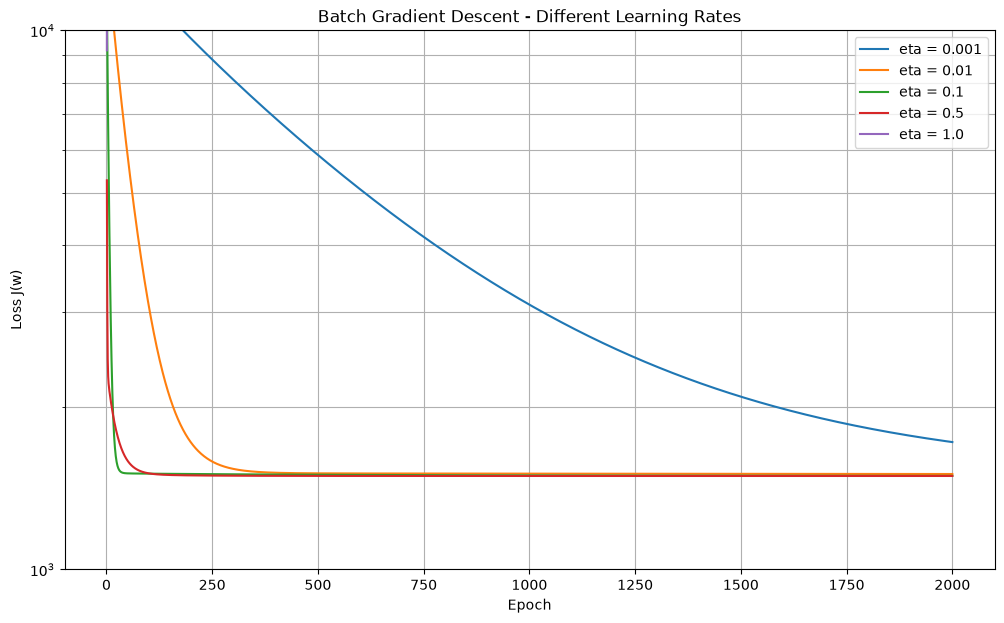

In [521]:
import matplotlib.pyplot as plt
import numpy as np

plt.close('all')

fig, ax = plt.subplots(figsize=(12, 7))

for eta, result in gd_results.items():

    losses = result["losses"]

    epochs = np.arange(1, len(losses) + 1)

    valid = np.isfinite(losses) & (losses > 0)

    print(f"Eta {eta}: plotting {np.sum(valid)} points")

    ax.plot(
        epochs[valid],
        losses[valid],
        label=f"eta = {eta}"
    )

ax.set_yscale('log')
ax.set_ylim(1000, 10000)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss J(w)")
ax.set_title("Batch Gradient Descent - Different Learning Rates")

ax.legend()
ax.grid(True, which='both')

plt.show()

In [522]:

results = []

for eta, result in gd_results.items():

    losses = result["losses"]
    distances = result["distances"]

    diverged = len(losses) < 2000

    if len(losses) == 0:
        final_loss = np.nan
        final_distance = np.nan
        first_epoch = "Diverged"

    else:
        final_loss = losses[-1]
        final_distance = distances[-1]

        reached = np.where(distances < 1e-3)[0]

        if len(reached) > 0:
            first_epoch = reached[0] + 1
        elif diverged:
            first_epoch = "Diverged"
        else:
            first_epoch = "Not reached"

    results.append({
        "Learning Rate": eta,
        "Final Loss": final_loss,
        "Final Relative Distance": final_distance,
        "First Epoch < 1e-3": first_epoch
    })

results_table = pd.DataFrame(results)
print(results_table.to_string(index=False))


 Learning Rate    Final Loss  Final Relative Distance First Epoch < 1e-3
         0.001  1.723403e+03             4.051131e-01        Not reached
         0.010  1.503687e+03             3.345214e-01        Not reached
         0.100  1.491893e+03             8.179229e-02        Not reached
         0.500  1.491146e+03             1.546262e-04               1524
         1.000 1.035714e+305            1.354569e+150           Diverged


In [523]:
N = len(y_train)
H = (X_train_bias.T @ X_train_bias) / N

eigenvalues = np.linalg.eigvalsh(H)
lambda_max = np.max(eigenvalues)
eta_threshold = 2 / lambda_max

print("Largest eigenvalue:", lambda_max)
print("Convergence threshold:", eta_threshold)

# Learning rates around the threshold
eta_below = 0.95 * eta_threshold
eta_above = 1.05 * eta_threshold

# Run gradient descent
w_below, loss_below, dist_below = batch_gradient_descent(
    X_train_bias, y_train, eta_below, 2000,w_star
)

w_above, loss_above, dist_above = batch_gradient_descent(
    X_train_bias, y_train, eta_above, 2000,w_star
)

print("\nLearning rate below threshold:", eta_below)
print("Final distance:", dist_below[-1])

print("\nLearning rate above threshold:", eta_above)
print("Final distance:", dist_above[-1])

Largest eigenvalue: 3.954755032050376
Convergence threshold: 0.5057203249737274

Learning rate below threshold: 0.48043430872504106
Final distance: 0.000210230753136441

Learning rate above threshold: 0.5310063412224139
Final distance: 7.581863342433239e+81


////////////////////////////////////////////////////////
////////////////////////////////////////////////////////
////////////////////////////////////////////////////////
////////////////////////////////////////////////////////

In [524]:
# raw data
X_train_raw = add_bias(X_train)
X_val_raw = add_bias(X_val)
X_test_raw = add_bias(X_test)

In [525]:
# Standardized features
H_std = (X_train_bias.T @ X_train_bias) / N
eigenvalues_std = np.linalg.eigvalsh(H_std)
cond_std = np.linalg.cond(X_train_bias.T @ X_train_bias)
eta_max_std = 2 / np.max(eigenvalues_std)


# Raw features
H_raw = (X_train_raw.T @ X_train_raw) / N
eigenvalues_raw = np.linalg.eigvalsh(H_raw)
cond_raw = np.linalg.cond(X_train_raw.T @ X_train_raw)
eta_max_raw = 2 / np.max(eigenvalues_raw)


print("Standardized features:")
print("Condition number:", cond_std)
print("Maximum learning rate:", eta_max_std)

print("\nRaw features:")
print("Condition number:", cond_raw)
print("Maximum learning rate:", eta_max_raw)

Standardized features:
Condition number: 505.70612269609745
Maximum learning rate: 0.5057203249737274

Raw features:
Condition number: 55778473.21759959
Maximum learning rate: 2.7427928748390996e-05


In [526]:

def batch_gd_raw(X, y, eta, epochs, w_star):
    w = np.zeros(X.shape[1])

    losses = []
    distances = []

    for epoch in range(epochs):

        gradient = linear_gradient(X, y, w)

        if not np.all(np.isfinite(gradient)):
            break

        w = w - eta * gradient

        current_loss = linear_loss(X, y, w)

        distance = (
            np.linalg.norm(w - w_star) /
            np.linalg.norm(w_star)
        )

        if not np.isfinite(current_loss) or not np.isfinite(distance):
            break

        losses.append(current_loss)
        distances.append(distance)

    return w, np.array(losses), np.array(distances)

In [527]:

w_star_raw = normal_equation(X_train_raw, y_train)

raw_learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]
raw_results = {}

for eta in raw_learning_rates:

    w, losses, distances = batch_gd_raw(
        X_train_raw,
        y_train,
        eta,
        2000,
        w_star_raw
    )

    raw_results[eta] = {
        "weights": w,
        "losses": losses,
        "distances": distances
    }


/home/asmaa/myenv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


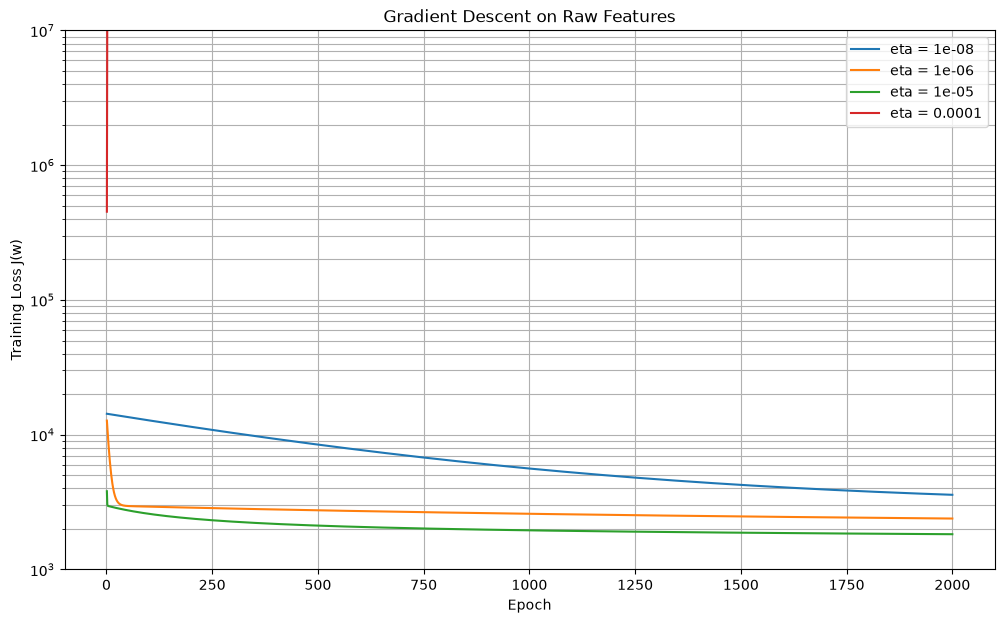

In [528]:
plt.close('all')
fig, ax = plt.subplots(figsize=(12, 7))
for eta, result in raw_results.items():

    losses = result["losses"]
    epochs = np.arange(1, len(losses) + 1)
    valid = np.isfinite(losses) & (losses > 0)
    ax.plot(
        epochs[valid],
        losses[valid],
        label=f"eta = {eta}"
    )

# Set a viewing range that shows the initial divergence
ax.set_ylim(1000, 1e7)

ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss J(w)")
ax.set_title("Gradient Descent on Raw Features")

ax.legend()
ax.grid(True, which="both")

plt.show()

In [529]:

results = []

for eta, result in raw_results.items():

    losses = result["losses"]
    distances = result["distances"]

    diverged = len(losses) < 2000

    if len(losses) == 0:
        final_loss = np.nan
        final_distance = np.nan
        first_epoch = "Diverged"

    else:
        final_loss = losses[-1]
        final_distance = distances[-1]

        reached = np.where(distances < 1e-3)[0]

        if len(reached) > 0:
            first_epoch = reached[0] + 1
        elif diverged:
            first_epoch = "Diverged"
        else:
            first_epoch = "Not reached"

    results.append({
        "Learning Rate": eta,
        "Final Loss": final_loss,
        "Final Relative Distance": final_distance,
        "First Epoch < 1e-3": first_epoch
    })

print(pd.DataFrame(results).to_string(index=False))

 Learning Rate    Final Loss  Final Relative Distance First Epoch < 1e-3
  1.000000e-08  3.583532e+03             9.999986e-01        Not reached
  1.000000e-06  2.388753e+03             9.999676e-01        Not reached
  1.000000e-05  1.827535e+03             9.998464e-01        Not reached
  1.000000e-04 2.484752e+304            2.172173e+147           Diverged


In [530]:
J_star_raw = linear_loss(
    X_train_raw,
    y_train,
    w_star_raw
)

print("Optimal raw training loss:", J_star_raw)

Optimal raw training loss: 1491.1459048007398


The condition number increases from approximately 505.71 for standardized features to 55,778,473.22 for raw features, indicating that the raw feature matrix is much more poorly conditioned. This also reduces the maximum usable learning rate from approximately 0.50572 to 0.00002743, making much smaller learning rates necessary for raw features. As a result, gradient descent makes much slower progress on raw features and requires many more epochs to approach the optimal solution. After 2000 epochs, none of the tested raw learning rates gets close to the optimal loss, while the learning rate 10^-4, which exceeds the convergence threshold, diverges.

//////////////////////////////////////////////////////
//////////////////////////////////////////////////////
//////////////////////////////////////////////////////
//////////////////////////////////////////////////////

In [531]:
def mini_batch_gd(X, y, eta, epochs, batch_size):
    N, d = X.shape
    w = np.zeros(d)

    losses = []
    updates = []

    rng = np.random.default_rng(42)

    updates_per_epoch = int(np.ceil(N / batch_size))
    total_updates = 0

    for epoch in range(epochs):

        # Shuffle training indices every epoch
        indices = rng.permutation(N)

        # Divide into batches
        for start in range(0, N, batch_size):

            batch_indices = indices[start:start + batch_size]

            X_batch = X[batch_indices]
            y_batch = y[batch_indices]

            # Calculate batch gradient
            gradient = linear_gradient(
                X_batch,
                y_batch,
                w
            )

            # Update weights
            w = w - eta * gradient
            total_updates += 1

        # Calculate loss on the complete training set
        losses.append(linear_loss(X, y, w))
        updates.append(total_updates)

    return w, np.array(losses), np.array(updates)

In [532]:
batch_sizes = [1, 16, 64, N]
mini_results = {}
for B in batch_sizes:
    

    w, losses, updates = mini_batch_gd(
        X_train_bias,
        y_train,
        eta=0.01,
        epochs=100,
        batch_size=B
    )

    mini_results[B] = {
        "weights": w,
        "losses": losses,
        "updates": updates
    }

In [533]:
for B in batch_sizes:
    print(
        f"B = {B}: "
        f"Total parameter updates = {mini_results[B]['updates'][-1]}, "     
        f"{len(mini_results[B]['losses'])} losses, "
        f"{len(mini_results[B]['updates'])} updates"
    )

B = 1: Total parameter updates = 26400, 100 losses, 100 updates
B = 16: Total parameter updates = 1700, 100 losses, 100 updates
B = 64: Total parameter updates = 500, 100 losses, 100 updates
B = 264: Total parameter updates = 100, 100 losses, 100 updates


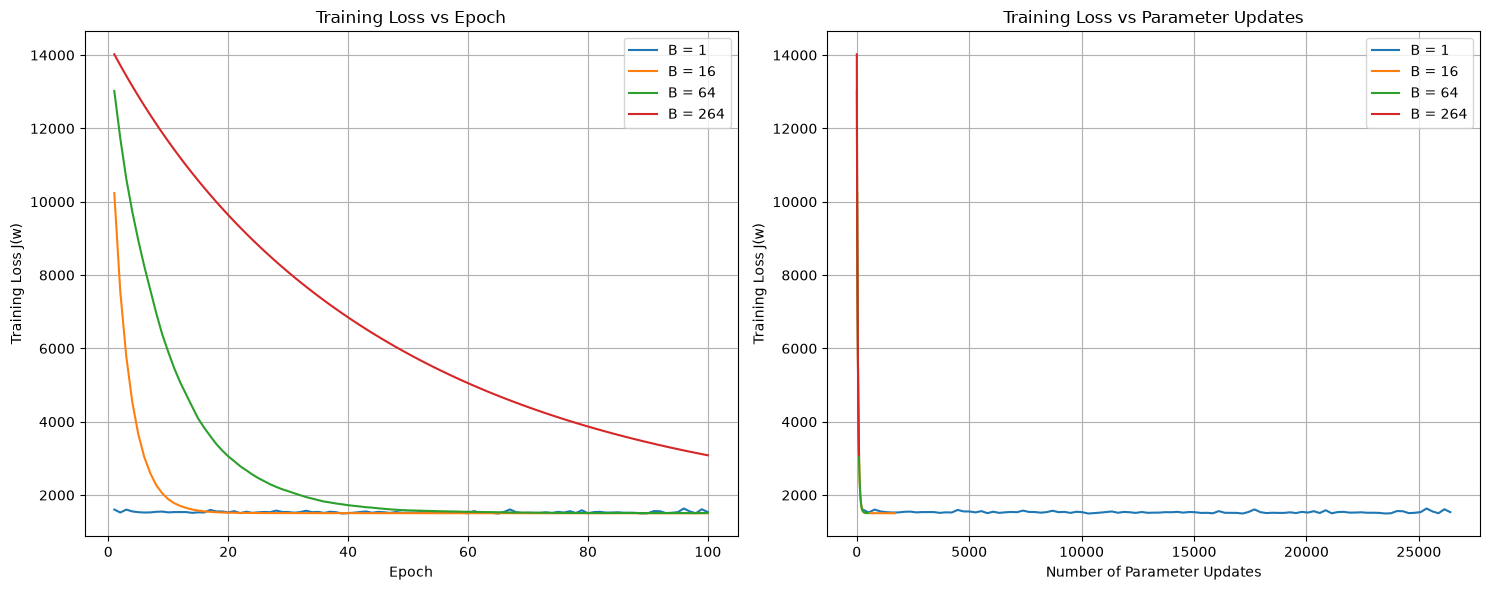

In [534]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for B in batch_sizes:

    result = mini_results[B]
    # Left panel: Loss vs Epoch
    epochs = np.arange(1, len(result["losses"]) + 1)

    axes[0].plot(
        epochs,
        result["losses"],
        label=f"B = {B}"
    )

    # Right panel: Loss vs Parameter Updates
    axes[1].plot(
        result["updates"],
        result["losses"],
        label=f"B = {B}"
    )

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss J(w)")
axes[0].set_title("Training Loss vs Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].set_xlabel("Number of Parameter Updates")
axes[1].set_ylabel("Training Loss J(w)")
axes[1].set_title("Training Loss vs Parameter Updates")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Best per epoch:B=1 (SGD), because it performs the largest number of parameter updates per epoch and reaches a low training loss quickly.

Best per parameter update: B=64, because it achieves a good reduction in loss with relatively few updates while maintaining stable progress.

For B=1, each update uses only one training example to calculate the gradient.

That gradient may not represent the direction that reduces the loss across the entire dataset. Different samples can produce different gradient directions, so the weights keep changing in somewhat different directions.

For larger batches, gradients are averaged across more samples, making the updates more stable.

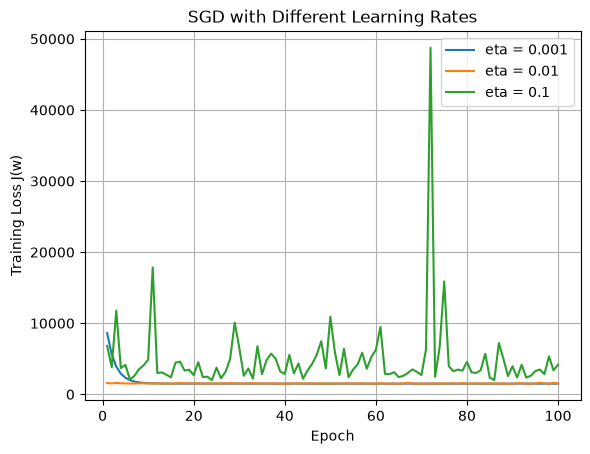

In [535]:
sgd_rates = [0.001, 0.01, 0.1]
sgd_results = {}
for eta in sgd_rates:

    w, losses, updates = mini_batch_gd(
        X_train_bias,
        y_train,
        eta=eta,
        epochs=100,
        batch_size=1
    )

    sgd_results[eta] = losses

# Plot
for eta in sgd_rates:

    plt.plot(
        range(1, 101),
        sgd_results[eta],
        label=f"eta = {eta}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss J(w)")
plt.title("SGD with Different Learning Rates")
plt.legend()
plt.grid(True)

plt.show()

When using B=1, increasing the learning rate from 0.001 to 0.01 makes the loss decrease faster but also increases its fluctuations. At eta=0.1, the loss becomes highly unstable, with large spikes because the updates are too large. Therefore, increasing the learning rate generally increases the noise and can make SGD unstable.

/////////////////////////////////////////////////////////
/////////////////////////////////////////////////////////
/////////////////////////////////////////////////////////

Jλ(w) = (1 / 2N) ||X̃w - y||² + (λ / 2) ||w₁:||²
Jλ(w) = (1 / 2N)(X̃w - y)ᵀ(X̃w - y) + (λ / 2)wᵀI₀w

Differentiate:
∇Jλ(w) = (1 / N)X̃ᵀ(X̃w - y) + λI₀w
(1 / N)X̃ᵀ(X̃w - y) + λI₀w = 0
(1 / N)X̃ᵀX̃w - (1 / N)X̃ᵀy + λI₀w = 0
(1 / N)X̃ᵀX̃w + λI₀w = (1 / N)X̃ᵀy
(X̃ᵀX̃ / N + λI₀)w = X̃ᵀy / N
w* = (X̃ᵀX̃ / N + λI₀)⁻¹ (X̃ᵀy / N)

In [536]:
X_example = np.array([
    [1, 1],
    [1, 2],
    [1, 3]
], dtype=float)

y_example = np.array([2, 3, 5], dtype=float)
lambda_example = 1
N_example = len(y_example)
I0_example = np.eye(X_example.shape[1])
I0_example[0, 0] = 0

A_example = (
    X_example.T @ X_example / N_example
    + lambda_example * I0_example
)

b_example = X_example.T @ y_example / N_example
w_example = np.linalg.solve(A_example, b_example)
print("Ridge weights:", w_example)

Ridge weights: [2.13333333 0.6       ]


In [537]:
def ridge_regression(X, y, lam):
    N, d = X.shape
    # Identity matrix
    I0 = np.eye(d)
    # Do not regularize the bias
    I0[0, 0] = 0

    A = (X.T @ X) / N + lam * I0
    b = (X.T @ y) / N
    w = np.linalg.solve(A, b)

    return w

In [538]:
lambda_values = np.concatenate((
    [0],
    np.logspace(-3, 1, 9)
))

ridge_original_results = {}

for lam in lambda_values:

    w = ridge_regression(
        X_train_bias,
        y_train,
        lam
    )

    train_pred = X_train_bias @ w
    val_pred = X_val_bias @ w
    test_pred = X_test_bias @ w

    ridge_original_results[lam] = {
        "weights": w,
        "train_rmse": rmse(y_train, train_pred),
        "val_rmse": rmse(y_val, val_pred),
        "test_rmse": rmse(y_test, test_pred)
    }

In [539]:
def degree2_expansion(X, feature_names):
    features = [X]
    names = list(feature_names)
    sex_index = list(feature_names).index("sex")

    for i in range(X.shape[1]):
        for j in range(i, X.shape[1]):

            # Drop sex squared
            if i == sex_index and j == sex_index:
                continue

            # Add product feature
            features.append(
                (X[:, i] * X[:, j]).reshape(-1, 1)
            )

            names.append(
                f"{feature_names[i]}*{feature_names[j]}"
            )

    return np.column_stack(features), names


# Create degree-2 features
X_train_exp, expanded_names = degree2_expansion(
    X_train,
    diabetes.feature_names
)

X_val_exp, _ = degree2_expansion(
    X_val,
    diabetes.feature_names
)

X_test_exp, _ = degree2_expansion(
    X_test,
    diabetes.feature_names
)

print("Expanded feature count:", X_train_exp.shape[1])


Expanded feature count: 64


In [540]:
expanded_scaler = Standardizer()
expanded_scaler.fit(X_train_exp)

X_train_exp_std = expanded_scaler.transform(X_train_exp)
X_val_exp_std = expanded_scaler.transform(X_val_exp)
X_test_exp_std = expanded_scaler.transform(X_test_exp)

# Add bias
X_train_exp_bias = add_bias(X_train_exp_std)
X_val_exp_bias = add_bias(X_val_exp_std)
X_test_exp_bias = add_bias(X_test_exp_std)

print("Training expanded shape:", X_train_exp_bias.shape)
print("Validation expanded shape:", X_val_exp_bias.shape)
print("Testing expanded shape:", X_test_exp_bias.shape)

# Condition number
cond_expanded = np.linalg.cond(
    X_train_exp_bias.T @ X_train_exp_bias
)

print("Expanded condition number:", cond_expanded)

Training expanded shape: (264, 65)
Validation expanded shape: (89, 65)
Testing expanded shape: (89, 65)
Expanded condition number: 1289356234.6280315


In [541]:
ridge_expanded_results = {}
for lam in lambda_values:

    w = ridge_regression(
        X_train_exp_bias,
        y_train,
        lam
    )

    train_pred = X_train_exp_bias @ w
    val_pred = X_val_exp_bias @ w
    test_pred = X_test_exp_bias @ w

    ridge_expanded_results[lam] = {
        "weights": w,
        "train_rmse": rmse(y_train, train_pred),
        "val_rmse": rmse(y_val, val_pred),
        "test_rmse": rmse(y_test, test_pred)
    }

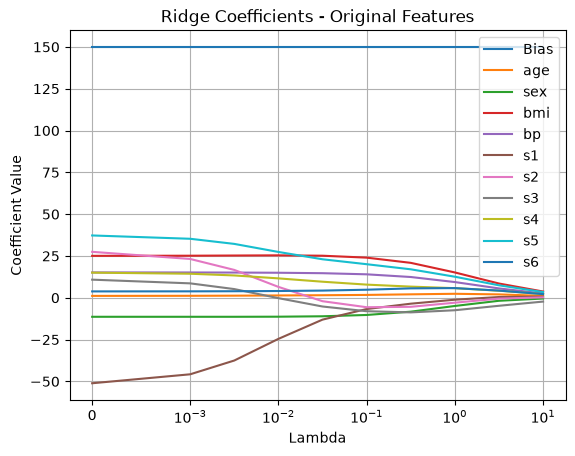

In [542]:
for i, name in enumerate(feature_names):
    coefficients = [
        ridge_original_results[lam]["weights"][i]
        for lam in lambda_values
    ]

    plt.plot(
        lambda_values,
        coefficients,
        label=name
    )

plt.xscale("symlog", linthresh=1e-3)
plt.xlabel("Lambda")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficients - Original Features")
plt.legend()
plt.grid(True)

plt.show()

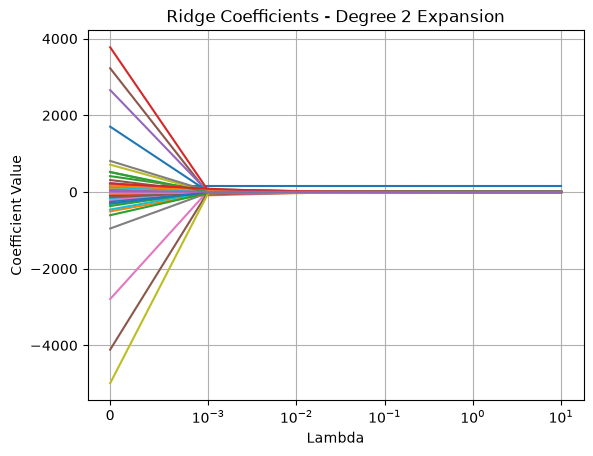

In [543]:

expanded_feature_names = ["Bias"] + expanded_names
for i, name in enumerate(expanded_feature_names):

    coefficients = [
        ridge_expanded_results[lam]["weights"][i]
        for lam in lambda_values
    ]

    plt.plot(
        lambda_values,
        coefficients,
        label=name
    )

plt.xscale("symlog", linthresh=1e-3)
plt.xlabel("Lambda")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficients - Degree 2 Expansion")
plt.grid(True)

plt.show()


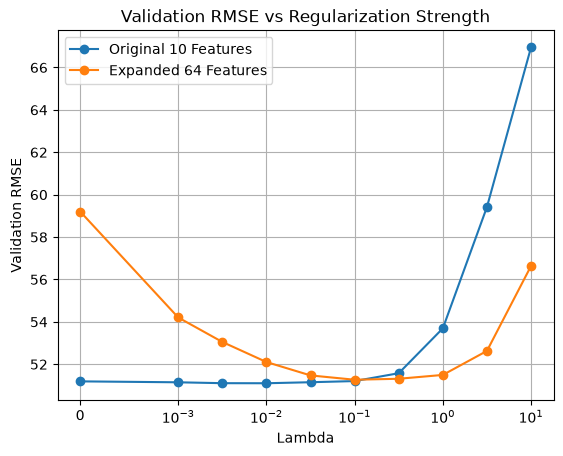

In [544]:
original_val_rmse = [
    ridge_original_results[lam]["val_rmse"]
    for lam in lambda_values
]

expanded_val_rmse = [
    ridge_expanded_results[lam]["val_rmse"]
    for lam in lambda_values
]

plt.plot(
    lambda_values,
    original_val_rmse,
    marker="o",
    label="Original 10 Features"
)

plt.plot(
    lambda_values,
    expanded_val_rmse,
    marker="o",
    label="Expanded 64 Features"
)

plt.xscale("symlog", linthresh=1e-3)
plt.xlabel("Lambda")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE vs Regularization Strength")
plt.legend()
plt.grid(True)

plt.show()

In [545]:
best_lambda_original = min(
    lambda_values,
    key=lambda lam: ridge_original_results[lam]["val_rmse"]
)

best_lambda_expanded = min(
    lambda_values,
    key=lambda lam: ridge_expanded_results[lam]["val_rmse"]
)

print("Best lambda - Original:",
      best_lambda_original)

print("Best lambda - Expanded:",
      best_lambda_expanded)

print("\nOriginal model:")
print("Lambda = 0 test RMSE:",
      ridge_original_results[0]["test_rmse"])

print("Best lambda test RMSE:",
      ridge_original_results[best_lambda_original]["test_rmse"])

print("\nExpanded model:")
print("Lambda = 0 test RMSE:",
      ridge_expanded_results[0]["test_rmse"])

print("Best lambda test RMSE:",
      ridge_expanded_results[best_lambda_expanded]["test_rmse"])


Best lambda - Original: 0.01
Best lambda - Expanded: 0.1

Original model:
Lambda = 0 test RMSE: 54.15641293326043
Best lambda test RMSE: 53.9584521494208

Expanded model:
Lambda = 0 test RMSE: 62.133373392121314
Best lambda test RMSE: 53.615580116744916


In [546]:
def ridge_gradient(X, y, w, lam):
    N = len(y)
    I0 = np.eye(X.shape[1])
    I0[0, 0] = 0

    gradient = (X.T @ (X @ w - y)) / N

    gradient += lam * (I0 @ w)

    return gradient


# Batch GD for Ridge
def ridge_gd(X, y, lam, eta, epochs):
    w = np.zeros(X.shape[1])
    for epoch in range(epochs):
        gradient = ridge_gradient(X, y, w, lam)
        w = w - eta * gradient

    return w

lambda_ridge = 0.1

w_ridge_closed = ridge_regression(
    X_train_bias,
    y_train,
    lambda_ridge
)

w_ridge_gd = ridge_gd(
    X_train_bias,
    y_train,
    lam=0.1,
    eta=0.4,
    epochs=3000
)

relative_distance = (
    np.linalg.norm(w_ridge_gd - w_ridge_closed)
    / np.linalg.norm(w_ridge_closed)
)

print("Relative distance:", relative_distance)
assert relative_distance < 1e-6
print("Ridge GD verification passed!")

Relative distance: 8.351521031972526e-16
Ridge GD verification passed!


In [547]:
from sklearn.linear_model import Ridge

ridge_sklearn = Ridge(
    alpha=0.1 * N
)

ridge_sklearn.fit(X_train_std, y_train)

w_ridge_sklearn = np.concatenate((
    [ridge_sklearn.intercept_],
    ridge_sklearn.coef_
))

print("Our Ridge weights:")
print(w_ridge_closed)

print("\nSklearn Ridge weights:")
print(w_ridge_sklearn)

print("\nMaximum difference:",
      np.max(np.abs(w_ridge_closed - w_ridge_sklearn)))

assert np.allclose(
    w_ridge_closed,
    w_ridge_sklearn,
    atol=1e-6
)

print("\nRidge sklearn verification passed!")

Our Ridge weights:
[149.81060606   1.71520109 -10.27220329  24.00312667  14.036236
  -6.7220634   -5.63988748  -8.02979453   7.87619758  20.08247856
   4.82614217]

Sklearn Ridge weights:
[149.81060606   1.71520109 -10.27220329  24.00312667  14.036236
  -6.7220634   -5.63988748  -8.02979453   7.87619758  20.08247856
   4.82614217]

Maximum difference: 1.5720758028692217e-13

Ridge sklearn verification passed!


Ridge regularization provides only a small improvement with the original 10 features because the number of features is relatively small compared with the number of training samples, so overfitting is limited. However, the degree-2 expansion increases the number of features to 64 while the training set still contains only 264 samples, making the model more likely to overfit. Ridge reduces the effect of this overfitting by penalizing large feature coefficients, improving generalization on the validation and test sets. The bias must not be penalized because it represents the intercept of the model, and penalizing it would unnecessarily restrict the model's ability to adjust its predictions' baseline.

////////////////////////////////////////////////////////
////////////////////////////////////////////////////////
////////////////////////////////////////////////////////
////////////////////////////////////////////////////////

In [548]:
import time
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    SGDRegressor
)

In [549]:
comparison_results = []
def add_result(name, w, fit_time):

    predictions = X_test_bias @ w
    test_error = rmse(y_test, predictions)

    relative_distance = (
        np.linalg.norm(w - w_star)
        / np.linalg.norm(w_star)
    )

    comparison_results.append({
        "Method": name,
        "Test RMSE": test_error,
        "Relative Distance": relative_distance,
        "Fit Time (seconds)": fit_time
    })

In [550]:
start = time.perf_counter()
w_normal = normal_equation(
    X_train_bias,
    y_train
)

normal_time = time.perf_counter() - start

add_result(
    "Normal Equation",
    w_normal,
    normal_time
)

In [551]:
start = time.perf_counter()
w_batch, losses_batch, distances_batch = batch_gradient_descent(
    X_train_bias,
    y_train,
    eta=0.5,
    epochs=2000,
    w_star=w_star
)

batch_time = time.perf_counter() - start

add_result(
    "Batch GD",
    w_batch,
    batch_time
)

In [552]:
start = time.perf_counter()

w_mini, losses_mini, updates_mini = mini_batch_gd(
    X_train_bias,
    y_train,
    eta=0.01,
    epochs=100,
    batch_size=16
)

mini_time = time.perf_counter() - start

add_result(
    "Mini-batch GD",
    w_mini,
    mini_time
)


In [553]:
start = time.perf_counter()
w_ridge = ridge_regression(
    X_train_bias,
    y_train,
    lam=0.1
)

ridge_time = time.perf_counter() - start

add_result(
    "Ridge",
    w_ridge,
    ridge_time
)

In [554]:
linear_model = LinearRegression()
start = time.perf_counter()
linear_model.fit(X_train_std, y_train)
linear_time = time.perf_counter() - start
w_linear_sklearn = np.concatenate((
    [linear_model.intercept_],
    linear_model.coef_
))

add_result(
    "Sklearn LinearRegression",
    w_linear_sklearn,
    linear_time
)

In [555]:
ridge_model = Ridge(alpha=0.1 * N)
start = time.perf_counter()
ridge_model.fit(X_train_std, y_train)
ridge_sklearn_time = time.perf_counter() - start

w_ridge_sklearn = np.concatenate((
    [ridge_model.intercept_],
    ridge_model.coef_
))

add_result(
    "Sklearn Ridge",
    w_ridge_sklearn,
    ridge_sklearn_time
)

In [556]:
sgd_learning_rates = [0.001, 0.01, 0.1]
sgd_models = {}

for eta in sgd_learning_rates:

    model = SGDRegressor(
        penalty=None,
        learning_rate="constant",
        eta0=eta,
        max_iter=1000,
        tol=None,
        random_state=42
    )

    start = time.perf_counter()
    model.fit(X_train_std, y_train)
    fit_time = time.perf_counter() - start

    w_sgd = np.concatenate((
        [model.intercept_[0]],
        model.coef_
    ))

    add_result(
        f"SGDRegressor eta={eta}",
        w_sgd,
        fit_time
    )

    sgd_models[eta] = model

In [557]:
comparison_table = pd.DataFrame(comparison_results)
print(comparison_table.to_string(index=False))

                  Method  Test RMSE  Relative Distance  Fit Time (seconds)
         Normal Equation  54.156413       0.000000e+00            0.000437
                Batch GD  54.156254       1.546262e-04            0.080322
           Mini-batch GD  53.895449       3.421471e-01            0.048122
                   Ridge  53.708925       3.636136e-01            0.000469
Sklearn LinearRegression  54.156413       8.801221e-15            0.004518
           Sklearn Ridge  53.708925       3.636136e-01            0.005873
  SGDRegressor eta=0.001  54.088486       4.976050e-02            0.033381
   SGDRegressor eta=0.01  54.898061       5.031993e-02            0.023029
    SGDRegressor eta=0.1  71.449348       3.949685e-01            0.015040


In [ ]:
# Normal Equation vs LinearRegression
print(
    "Normal Equation vs LinearRegression:",
    np.max(np.abs(w_normal - w_linear_sklearn))
)

# Ridge vs sklearn Ridge
print(
    "Ridge vs sklearn Ridge:",
    np.max(np.abs(w_ridge - w_ridge_sklearn))
)

assert np.allclose(
    w_normal,
    w_linear_sklearn,
    atol=1e-10
)

assert np.allclose(
    w_ridge,
    w_ridge_sklearn,
    atol=1e-10
)

print("\nExact solver verification passed!")

Normal Equation vs LinearRegression: 1.0089706847793423e-12
Ridge vs sklearn Ridge: 1.5720758028692217e-13

Exact solver verification passed!


The Normal Equation and sklearn LinearRegression produce almost identical results because both calculate the same least-squares solution. Similarly, our Ridge implementation and sklearn Ridge agree because they use the same regularization objective when alpha = λ × N_train. However, gradient descent and SGDRegressor may produce different results because they use iterative optimization, and their accuracy depends on the learning rate and number of updates.